In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv(r"data/main.csv")
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_train_track_a_00001,"Colorado, middle of nowhere.",0,1,0,0,1
1,eng_train_track_a_00002,This involved swimming a pretty large lake tha...,0,1,0,0,0
2,eng_train_track_a_00003,It was one of my most shameful experiences.,0,1,0,1,0
3,eng_train_track_a_00004,"After all, I had vegetables coming out my ears...",0,0,0,0,0
4,eng_train_track_a_00005,Then the screaming started.,0,1,0,1,1


In [3]:
emotion_counts = {
    'anger': df['anger'].sum(),
    'fear': df['fear'].sum(),
    'joy': df['joy'].sum(),
    'sadness': df['sadness'].sum(),
    'surprise': df['surprise'].sum()
}

total_entries = len(df)

# Calculating percentages
emotion_percentages = {emotion: (count / total_entries) * 100 for emotion, count in emotion_counts.items()}

print("Emotion Distribution Analysis")
print("=" * 30)
print(f"Total entries: {total_entries}\n")

print("Absolute counts:")
for emotion, count in emotion_counts.items():
    print(f"{emotion.capitalize()}: {count}")

print("\nPercentages:")
for emotion, percentage in emotion_percentages.items():
    print(f"{emotion.capitalize()}: {percentage:.2f}%")

Emotion Distribution Analysis
Total entries: 2768

Absolute counts:
Anger: 333
Fear: 1611
Joy: 674
Sadness: 878
Surprise: 839

Percentages:
Anger: 12.03%
Fear: 58.20%
Joy: 24.35%
Sadness: 31.72%
Surprise: 30.31%


/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_80408/3478685322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')


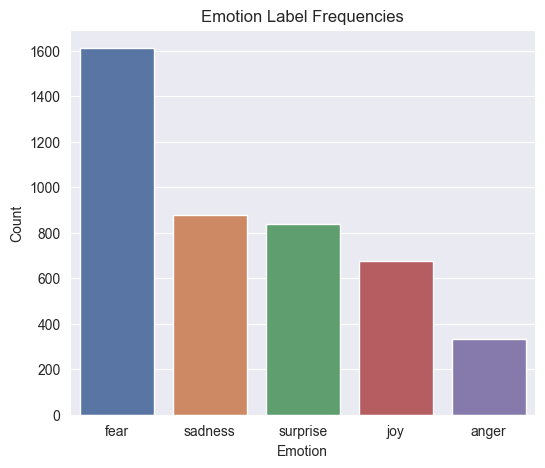

In [4]:
emotion_cols = ['anger', 'fear', 'joy', 'sadness', 'surprise']
label_counts = df[emotion_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(6, 5))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')
plt.title("Emotion Label Frequencies")
plt.ylabel("Count")
plt.xlabel("Emotion")
plt.show()

/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_80408/2437962607.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette='deep')


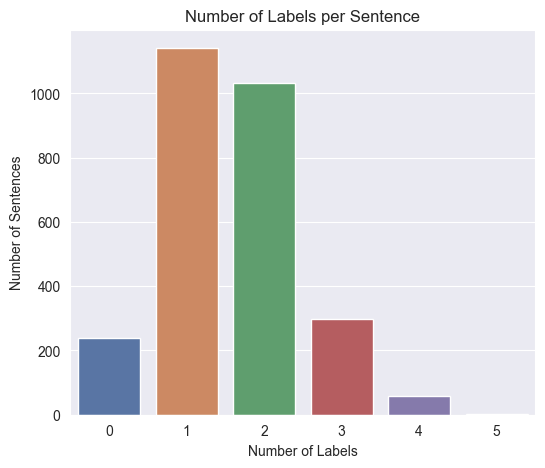

In [5]:
# Count how many labels each sentence has
df["num_labels"] = df[emotion_cols].sum(axis=1)
multilabel_sentences = df["num_labels"].value_counts().sort_index()

plt.figure(figsize=(6, 5))
sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette='deep')
plt.title("Number of Labels per Sentence")
plt.xlabel("Number of Labels")
plt.ylabel("Number of Sentences")
plt.show()

count    2768.000000
mean       15.477601
std        10.856667
min         1.000000
25%         8.000000
50%        13.000000
75%        20.000000
max        89.000000
Name: token_count, dtype: float64


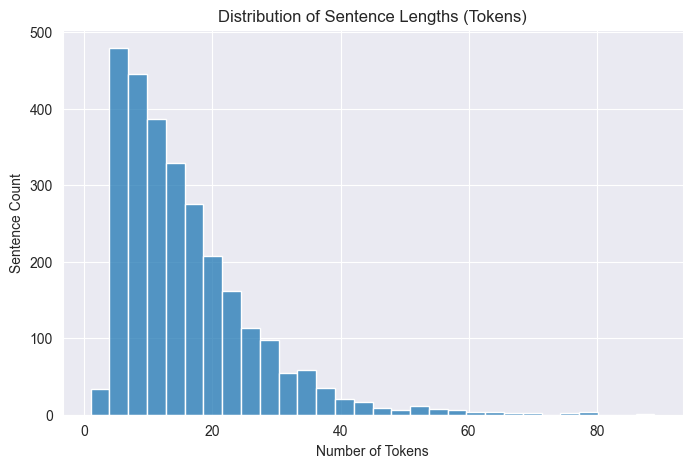

In [6]:
df["token_count"] = df["text"].apply(lambda x: len(str(x).split()))
print(df["token_count"].describe())

# Plot sentence length distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["token_count"], bins=30, kde=False)
plt.title("Distribution of Sentence Lengths (Tokens)")
plt.xlabel("Number of Tokens")
plt.ylabel("Sentence Count")
plt.show()

In [7]:
import nltk
import string

# Downloading necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [8]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

In [9]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

In [10]:
def preprocess(text):
    # Lowercasing
    text = text.lower()

    # Tokenizing
    tokens = word_tokenize(text)

    # Removing punctuation and stopwords, then stemming
    tokens = [stemmer.stem(word) for word in tokens if word not in string.punctuation and word not in stop_words]
    return " ".join(tokens)


In [11]:
df["processed_text"] = df["text"].apply(preprocess)


In [12]:
from sklearn.feature_extraction.text import CountVectorizer

# Example workflow
df['processed_text'] = df['text'].apply(preprocess)

emotions = ['anger', 'fear', 'joy', 'sadness', 'surprise']

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['processed_text'])
y = df[emotions]  #(n_samples, n_labels)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

from sklearn.naive_bayes import MultinomialNB
from sklearn.multiclass import OneVsRestClassifier

model = OneVsRestClassifier(MultinomialNB())
model.fit(X_train, y_train)

from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=emotions))

print("Exact Match Accuracy:", accuracy_score(y_test, y_pred))


              precision    recall  f1-score   support

       anger       0.26      0.10      0.14       105
        fear       0.68      0.79      0.73       496
         joy       0.45      0.26      0.33       185
     sadness       0.55      0.41      0.47       251
    surprise       0.56      0.34      0.42       264

   micro avg       0.60      0.50      0.54      1301
   macro avg       0.50      0.38      0.42      1301
weighted avg       0.56      0.50      0.52      1301
 samples avg       0.53      0.45      0.46      1301

Exact Match Accuracy: 0.23345367027677497


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: F-score is ill-defined a

In [13]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch
from sklearn.model_selection import train_test_split

# defining emotion lables 
emotions = ['anger', 'fear', 'joy', 'sadness', 'surprise']

X = df['text'].tolist()
y = df[emotions].values


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')


class EmotionDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        item = {key: val.squeeze() for key, val in encoding.items()}
        item['labels'] = torch.tensor(label, dtype=torch.float)
        return item


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
train_dataset = EmotionDataset(X_train, y_train, tokenizer)
test_dataset = EmotionDataset(X_test, y_test, tokenizer)


In [16]:
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(emotions),
    problem_type="multi_label_classification"
)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [17]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=8,
)


In [18]:
from transformers import BertForSequenceClassification

model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(['anger', 'fear', 'joy', 'sadness', 'surprise']),
    problem_type="multi_label_classification"
)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [19]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)


In [20]:
from transformers import TrainingArguments

help(TrainingArguments)


Help on class TrainingArguments in module transformers.training_args:

class TrainingArguments(builtins.object)
 |  TrainingArguments(
 |      output_dir: Optional[str] = None,
 |      overwrite_output_dir: bool = False,
 |      do_train: bool = False,
 |      do_eval: bool = False,
 |      do_predict: bool = False,
 |      eval_strategy: Union[transformers.trainer_utils.IntervalStrategy, str] = 'no',
 |      prediction_loss_only: bool = False,
 |      per_device_train_batch_size: int = 8,
 |      per_device_eval_batch_size: int = 8,
 |      per_gpu_train_batch_size: Optional[int] = None,
 |      per_gpu_eval_batch_size: Optional[int] = None,
 |      gradient_accumulation_steps: int = 1,
 |      eval_accumulation_steps: Optional[int] = None,
 |      eval_delay: Optional[float] = 0,
 |      torch_empty_cache_steps: Optional[int] = None,
 |      learning_rate: float = 5e-05,
 |      weight_decay: float = 0.0,
 |      adam_beta1: float = 0.9,
 |      adam_beta2: float = 0.999,
 |      ada

In [21]:
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(emotions),
    problem_type="multi_label_classification"
)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [22]:
trainer.train()


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss
500,0.381600


TrainOutput(global_step=554, training_loss=0.3702048618440594, metrics={'train_runtime': 134.9779, 'train_samples_per_second': 32.805, 'train_steps_per_second': 4.104, 'total_flos': 291271783707648.0, 'train_loss': 0.3702048618440594, 'epoch': 2.0})

In [23]:
preds = trainer.predict(test_dataset)


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


In [24]:
import torch

y_pred_probs = torch.sigmoid(torch.tensor(preds.predictions)).numpy()
y_pred = (y_pred_probs >= 0.5).astype(int)


In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=emotions))

print(accuracy_score(y_test, y_pred))


              precision    recall  f1-score   support

       anger       0.69      0.35      0.46        72
        fear       0.80      0.86      0.83       330
         joy       0.74      0.56      0.63       115
     sadness       0.67      0.65      0.66       167
    surprise       0.81      0.65      0.72       179

   micro avg       0.76      0.69      0.73       863
   macro avg       0.74      0.61      0.66       863
weighted avg       0.76      0.69      0.72       863
 samples avg       0.67      0.64      0.63       863

0.40794223826714804


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1706: UndefinedMetricWarning: F-score is ill-defined a

In [28]:
# Save the model properly in a format that can be loaded by from_pretrained
# This should be executed after training is complete
model_save_path = './results'
trainer.save_model(model_save_path)
print(f"Model saved to {model_save_path}")

# Verify the saved model
import os
print("Files saved in the model directory:")
for file in os.listdir(model_save_path):
    print(f"- {file}")

# Test loading the model
test_model = BertForSequenceClassification.from_pretrained(model_save_path)
print("Model loaded successfully!")

# The model can now be used in main.py

Model saved to ./results
Files saved in the model directory:
- model.safetensors
- checkpoint-554
- checkpoint-500
- config.json
- training_args.bin
Model loaded successfully!
